In [1]:
import pandas as pd
import numpy as np

# Create business dataset
data = {
    "Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [25, 30, 45, 50, 55, 65, 70, 80, 85, 95],
    "Customers": [100, 120, 150, 160, 180, 210, 220, 250, 270, 300]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Pearson correlation
pearson = df["Advertising"].corr(
    df["Sales"],
    method="pearson"
)

# Spearman correlation
spearman = df["Advertising"].corr(
    df["Sales"],
    method="spearman"
)

print("\nCorrelation Results")
print("Pearson Correlation:", round(pearson, 3))
print("Spearman Correlation:", round(spearman, 3))

Dataset:
   Advertising  Sales  Customers
0           10     25        100
1           15     30        120
2           20     45        150
3           25     50        160
4           30     55        180
5           35     65        210
6           40     70        220
7           45     80        250
8           50     85        270
9           55     95        300

Correlation Results
Pearson Correlation: 0.996
Spearman Correlation: 1.0


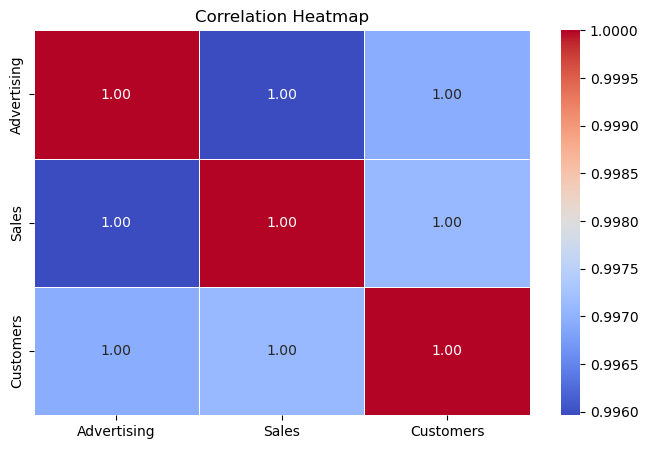

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = df.corr(method="pearson")

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

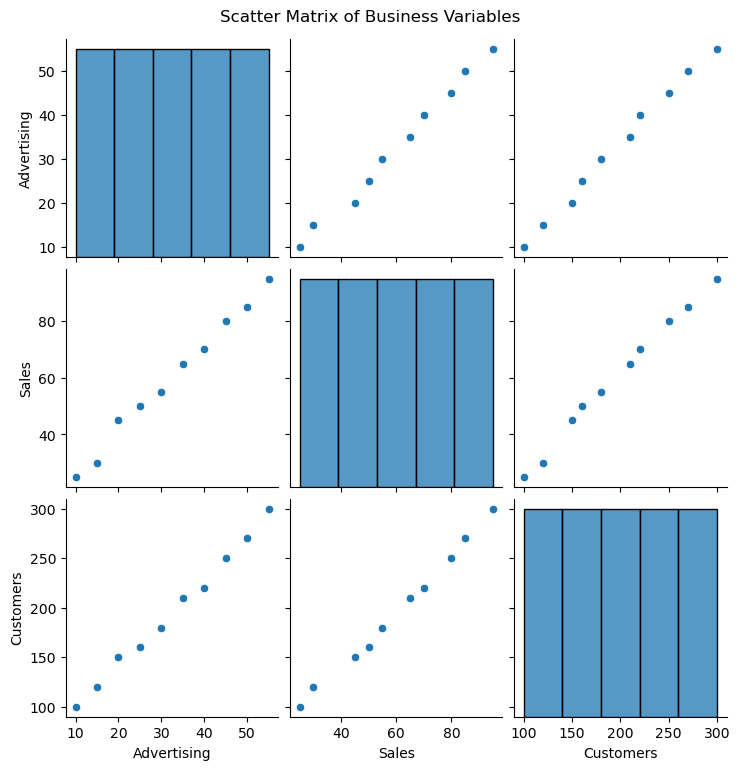

In [3]:
sns.pairplot(
    df,
    diag_kind="hist"
)

plt.suptitle(
    "Scatter Matrix of Business Variables",
    y=1.02
)

plt.show()

In [4]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Generate advertising expenditure
advertising = np.random.uniform(5, 50, 100)

# Generate sales with some random variation
sales = (
    8 + 2.5 * advertising +
    np.random.normal(0, 12, 100)
)

# Create dataset
model_df = pd.DataFrame({
    "Advertising": advertising,
    "Sales": sales
})

print(model_df.head())
print("\nDataset Shape:", model_df.shape)

   Advertising       Sales
0    21.854305   63.680328
1    47.782144  123.867271
2    37.939727  103.950448
3    31.939632   63.998252
4    12.020839   35.416034

Dataset Shape: (100, 2)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Independent and dependent variables
X = model_df[["Advertising"]]
y = model_df["Sales"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display model coefficients
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 10.250096746888715
Coefficient: 2.392972617322814


In [6]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

print("\nModel Evaluation")
print("R2 Score:", round(r2, 3))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))


Model Evaluation
R2 Score: 0.919
MAE: 7.096
RMSE: 9.702


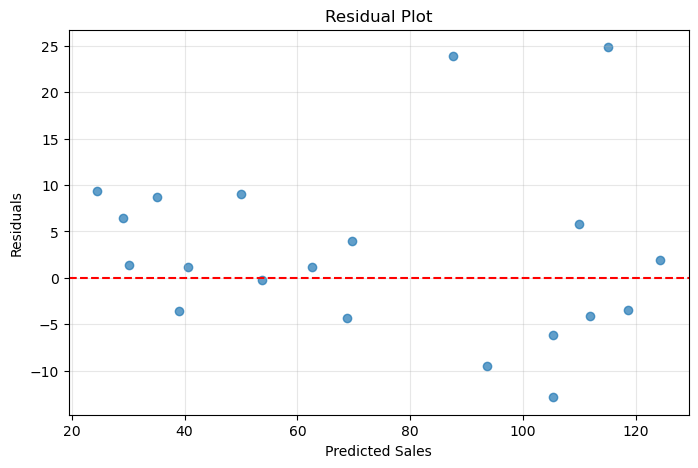

In [7]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.grid(alpha=0.3)
plt.show()

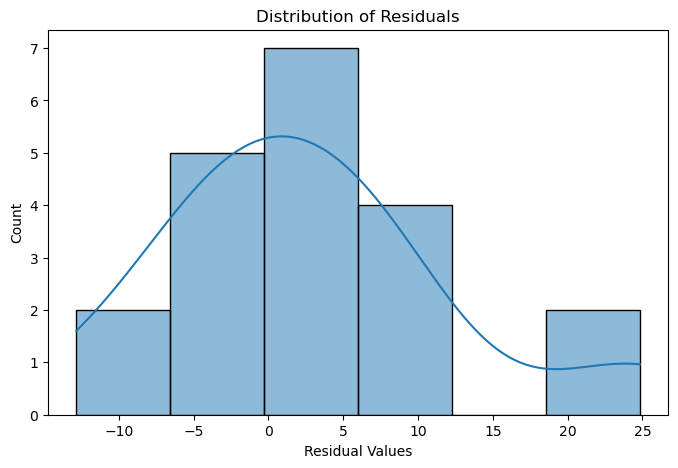

In [8]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Values")

plt.show()

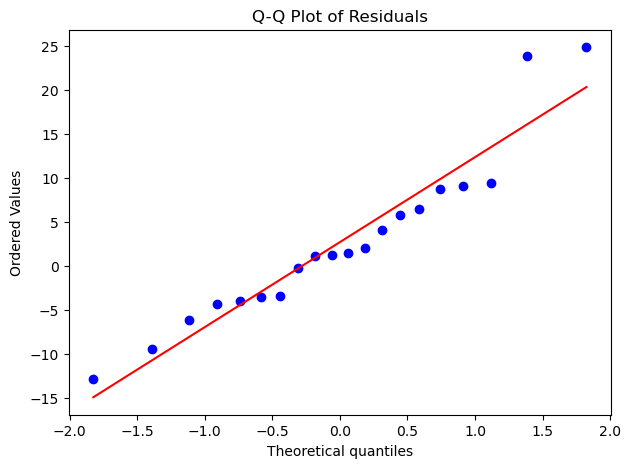

In [9]:
from scipy import stats

plt.figure(figsize=(7, 5))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals")
plt.show()